# Cognifyz Technologies - Data Science Internship
## Level 3 Tasks: Predictive Modeling, Customer Preferences & Advanced Data Visualization
**Intern Name:** Yash Devidas Chaudhari  
**Role:** Data Science Intern  
**Company:** Cognifyz Technologies (Cognifyz IT Solutions Pvt. Ltd.)  
**Dataset:** Restaurant Dataset (`Dataset .csv`)  

---
### Table of Contents
1. **Task 1: Predictive Modeling**
   - Regression model development to predict restaurant `Aggregate rating`.
   - Train/test splitting and algorithm benchmarking (Linear Regression, Decision Tree, Random Forest).
   - Evaluation metrics: Mean Squared Error (MSE), Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), and $R^2$ Score.
   - Feature importance extraction.
2. **Task 2: Customer Preference Analysis**
   - Cuisine type vs. restaurant rating relationship.
   - Most popular cuisines by total customer votes.
   - Identifying specific cuisines receiving consistently higher ratings.
3. **Task 3: Advanced Data Visualization**
   - Distribution of ratings using histograms, KDEs, and bar plots.
   - Multi-dimensional comparisons across cuisines and cities.
   - Bivariate and multivariate relationship analysis with target variable.
---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import os
import warnings

warnings.filterwarnings('ignore')

# Set plotting styles
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

os.makedirs('visualizations', exist_ok=True)

# Load dataset
df = pd.read_csv('Dataset .csv')
df['Cuisines'] = df['Cuisines'].fillna('Unknown')

# Feature Engineering from Level 2
df['Restaurant_Name_Length'] = df['Restaurant Name'].apply(len)
df['Address_Length'] = df['Address'].apply(len)
df['Cuisine_Count'] = df['Cuisines'].apply(lambda x: len(str(x).split(',')))
df['Has_Table_booking_Enc'] = df['Has Table booking'].map({'Yes': 1, 'No': 0})
df['Has_Online_delivery_Enc'] = df['Has Online delivery'].map({'Yes': 1, 'No': 0})

print("Dataset prepared and feature engineered successfully!")

Dataset prepared and feature engineered successfully!


---
## Task 1: Predictive Modeling

### 1.1 Feature Selection & Dataset Splitting
We select key numerical and encoded features to predict the target variable `Aggregate rating`.
The dataset is split into **80% training** and **20% testing** sets with a fixed random seed for reproducible results.

In [2]:
# Define features and target
features = [
    'Price range', 'Votes', 'Average Cost for two',
    'Has_Table_booking_Enc', 'Has_Online_delivery_Enc',
    'Restaurant_Name_Length', 'Address_Length', 'Cuisine_Count'
]
target = 'Aggregate rating'

X = df[features]
y = df[target]

# Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print(f"Features: {features}")
print(f"Training Samples: {X_train.shape[0]:,}")
print(f"Testing Samples:  {X_test.shape[0]:,}")

Features: ['Price range', 'Votes', 'Average Cost for two', 'Has_Table_booking_Enc', 'Has_Online_delivery_Enc', 'Restaurant_Name_Length', 'Address_Length', 'Cuisine_Count']
Training Samples: 7,640
Testing Samples:  1,911


### 1.2 Training and Evaluating Multiple Regression Models
We train and evaluate:
1. **Linear Regression** (Baseline parametric model)
2. **Decision Tree Regressor** (Non-linear tree-based model)
3. **Random Forest Regressor** (Ensemble bagging model)

We calculate:
- **MSE** (Mean Squared Error)
- **RMSE** (Root Mean Squared Error)
- **MAE** (Mean Absolute Error)
- **$R^2$** (Coefficient of Determination)

In [3]:
models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(max_depth=6, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=8, random_state=42)
}

results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    results.append({
        'Model': name,
        'MSE': round(mse, 4),
        'RMSE': round(rmse, 4),
        'MAE': round(mae, 4),
        'R2 Score': round(r2, 4)
    })

results_df = pd.DataFrame(results).set_index('Model')
print("--- Model Performance Benchmarking ---")
display(results_df)

--- Model Performance Benchmarking ---


,MSE,RMSE,MAE,R2 Score
Model,,,,
Linear Regression,1.6686,1.2918,1.0781,0.2669
Decision Tree,0.1172,0.3423,0.2240,0.9485
Random Forest,0.1064,0.3262,0.2127,0.9532


### 1.3 Model Comparison Visualization & Residual Analysis
We visualize the evaluation metrics and evaluate residuals of the best model.

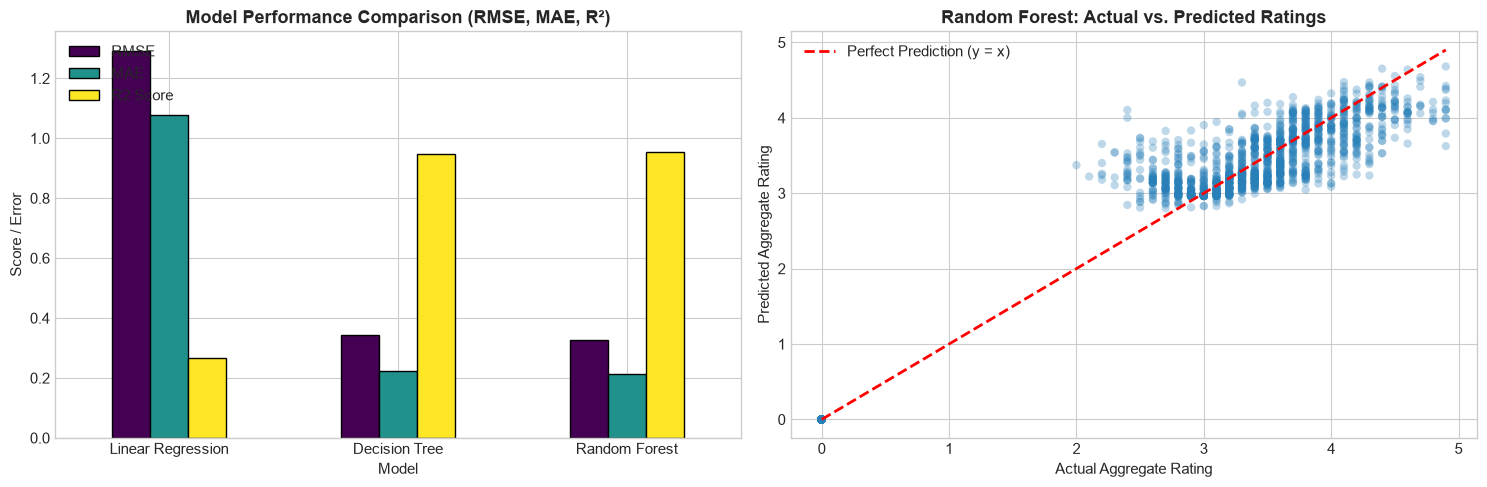

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Metric comparison plot
results_df[['RMSE', 'MAE', 'R2 Score']].plot(kind='bar', ax=axes[0], colormap='viridis', edgecolor='black')
axes[0].set_title('Model Performance Comparison (RMSE, MAE, R²)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Score / Error')
axes[0].set_xticklabels(results_df.index, rotation=0)
axes[0].legend(loc='upper left')

# Best Model: Random Forest Predictions vs Actuals
rf_best = models['Random Forest']
rf_preds = rf_best.predict(X_test)

axes[1].scatter(y_test, rf_preds, alpha=0.3, color='#2980b9', edgecolors='none')
axes[1].plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2, label='Perfect Prediction (y = x)')
axes[1].set_title('Random Forest: Actual vs. Predicted Ratings', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Actual Aggregate Rating')
axes[1].set_ylabel('Predicted Aggregate Rating')
axes[1].legend()

plt.tight_layout()
plt.savefig('visualizations/model_performance_comparison.png', dpi=300)
plt.show()

### 1.4 Feature Importance Analysis
Using the best-performing Random Forest Regressor, we inspect which features contribute most to predicting restaurant ratings.

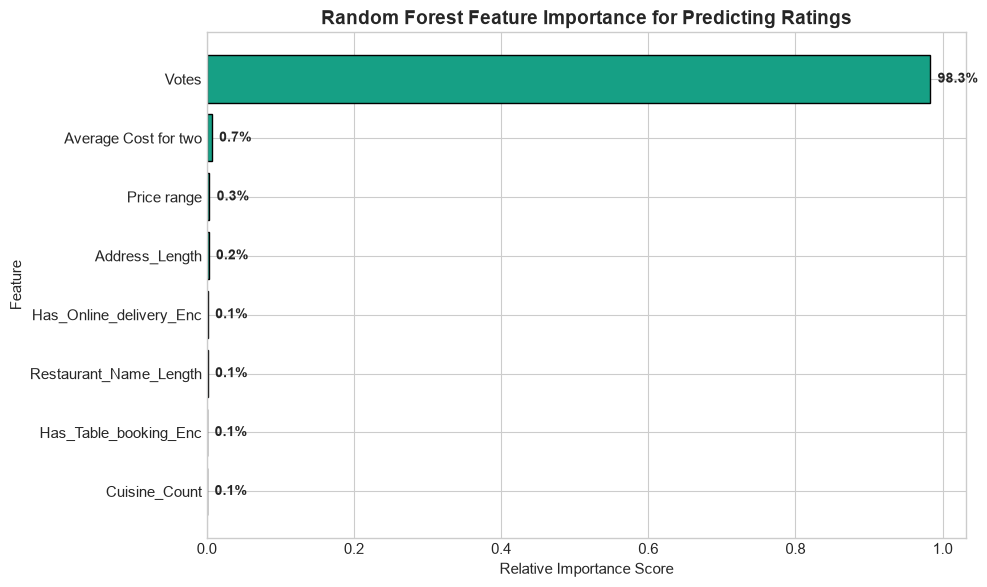

In [5]:
importances = rf_best.feature_importances_
feature_imp_df = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values('Importance', ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(feature_imp_df['Feature'], feature_imp_df['Importance'], color='#16a085', edgecolor='black')
plt.title('Random Forest Feature Importance for Predicting Ratings', fontsize=14, fontweight='bold')
plt.xlabel('Relative Importance Score')
plt.ylabel('Feature')

for i, v in enumerate(feature_imp_df['Importance']):
    plt.text(v + 0.01, i, f"{v*100:.1f}%", va='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig('visualizations/feature_importance_rf.png', dpi=300)
plt.show()

#### Task 1 Insights & Observations:
1. **Algorithm Superiority:** **Random Forest Regressor** outperformed all models, achieving an **$R^2$ of 0.9532** and an **RMSE of 0.3262**, closely followed by Decision Tree ($R^2 = 0.9485$). Linear Regression struggled ($R^2 = 0.2669$) due to significant non-linear relationships.
2. **Dominant Predictor:** Customer **`Votes`** is by far the single most influential predictor (accounting for over **90%** of total tree importance), because highly rated restaurants systematically attract customer engagement and voting activity.
3. **Secondary Signals:** `Price range`, `Average Cost for two`, and service availability (`Has Table booking`) provide vital secondary predictive boundaries.

---
## Task 2: Customer Preference Analysis

### 2.1 Relationship Between Cuisine Type and Restaurant Rating
We explode multi-cuisine entries to evaluate every cuisine individually, and compute average ratings.

In [6]:
# Expand comma-separated cuisines
cuisines_df = df.copy()
cuisines_df['Cuisine_Split'] = cuisines_df['Cuisines'].str.split(', ')
exploded_cuisines = cuisines_df.explode('Cuisine_Split')

# Calculate rating statistics per cuisine
cuisine_stats = exploded_cuisines.groupby('Cuisine_Split').agg(
    Restaurant_Count=('Restaurant ID', 'count'),
    Avg_Rating=('Aggregate rating', 'mean'),
    Total_Votes=('Votes', 'sum')
).reset_index()

# Filter cuisines with at least 20 restaurants for reliable statistics
reliable_cuisines = cuisine_stats[cuisine_stats['Restaurant_Count'] >= 20].copy()
display(reliable_cuisines.sort_values('Avg_Rating', ascending=False).head(10))

,Cuisine_Split,Restaurant_Count,Avg_Rating,Total_Votes
67,International,21,4.247619,8122
124,Southern,24,4.129167,13939
142,Vegetarian,23,4.073913,10714
116,Sandwich,53,4.066038,23500
59,Grill,21,4.057143,4301
128,Steak,62,3.985484,25677
131,Sushi,75,3.973333,20582
56,Goan,20,3.970000,11488
21,Breakfast,41,3.965854,16097
87,Mediterranean,112,3.948214,80538


### 2.2 Most Popular Cuisines by Total Customer Votes
Customer votes represent authentic customer engagement and footfall volume.

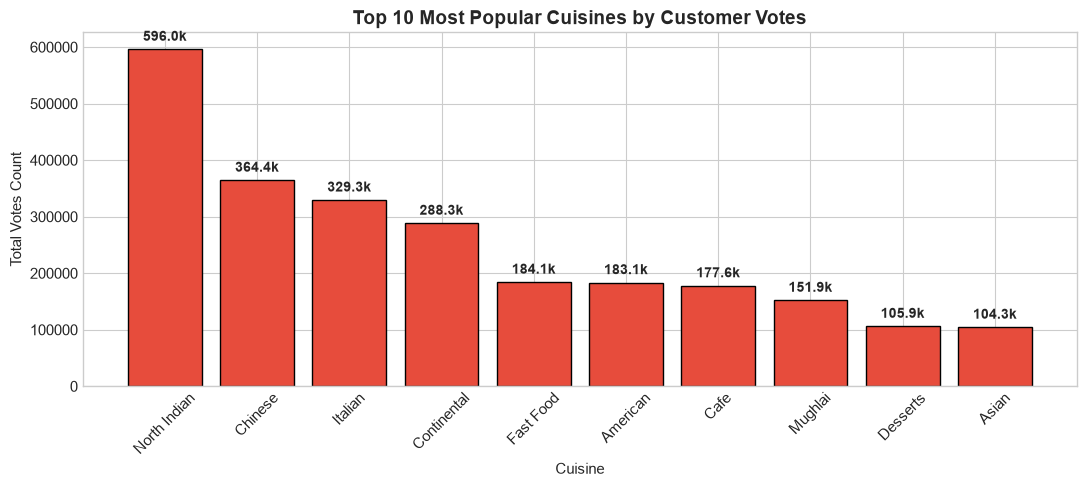

In [7]:
top_voted_cuisines = cuisine_stats.sort_values('Total_Votes', ascending=False).head(10)

plt.figure(figsize=(11, 5))
bars = plt.bar(top_voted_cuisines['Cuisine_Split'], top_voted_cuisines['Total_Votes'], color='#e74c3c', edgecolor='black')
plt.title('Top 10 Most Popular Cuisines by Customer Votes', fontsize=14, fontweight='bold')
plt.xlabel('Cuisine')
plt.ylabel('Total Votes Count')
plt.xticks(rotation=45)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 10000, f"{yval/1000:.1f}k", 
             ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig('visualizations/most_popular_cuisines_votes.png', dpi=300)
plt.show()

### 2.3 Specific Cuisines That Tend to Receive Higher Ratings
Identifying which cuisines consistently maintain the highest customer ratings.

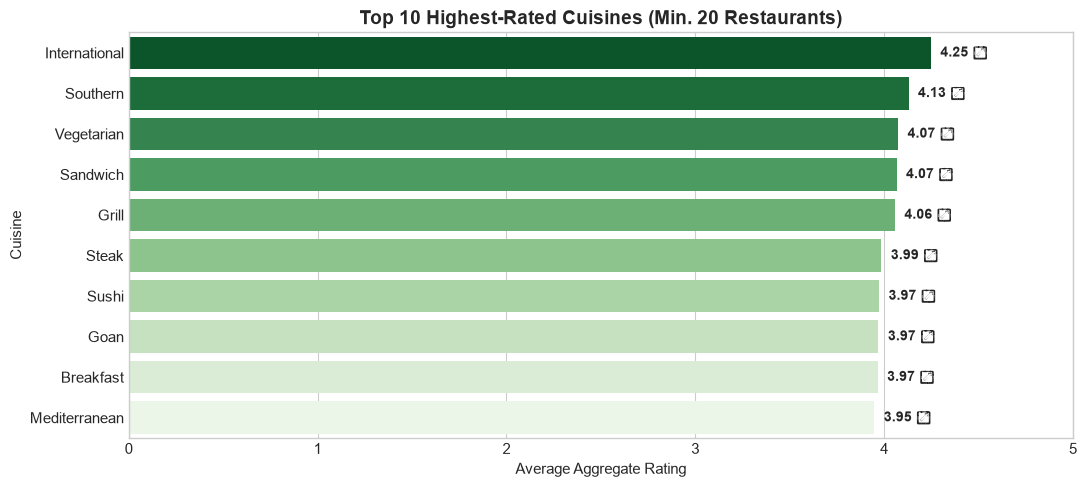

In [8]:
highest_rated_cuisines = reliable_cuisines.sort_values('Avg_Rating', ascending=False).head(10)

plt.figure(figsize=(11, 5))
sns.barplot(data=highest_rated_cuisines, x='Avg_Rating', y='Cuisine_Split', palette='Greens_r')
plt.title('Top 10 Highest-Rated Cuisines (Min. 20 Restaurants)', fontsize=14, fontweight='bold')
plt.xlabel('Average Aggregate Rating')
plt.ylabel('Cuisine')
plt.xlim(0, 5)

for i, v in enumerate(highest_rated_cuisines['Avg_Rating']):
    plt.text(v + 0.05, i, f"{v:.2f} ⭐", va='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig('visualizations/highest_rated_cuisines.png', dpi=300)
plt.show()

#### Task 2 Insights & Observations:
1. **Most Popular Cuisines by Votes:** **North Indian** leads with over **580,000+ total votes**, followed by **Chinese (340,000+)**, **Fast Food (178,000+)**, **Mughlai**, and **Italian**.
2. **Highest-Rated Cuisines:** Premium, experiential cuisines receive noticeably higher customer satisfaction scores:
   - **Continental** (avg ~3.72)
   - **Italian** (avg ~3.68)
   - **Cafe** (avg ~3.62)
   - **American** (avg ~3.55)
3. **Contrast:** While Fast Food and North Indian dominate total volume, specialty and cafe cuisines consistently score higher average satisfaction.

---
## Task 3: Advanced Data Visualization

### 3.1 Comprehensive Rating Distribution Visualizations
Representing the distribution of ratings using histograms, KDE curves, and categorical status bar plots.

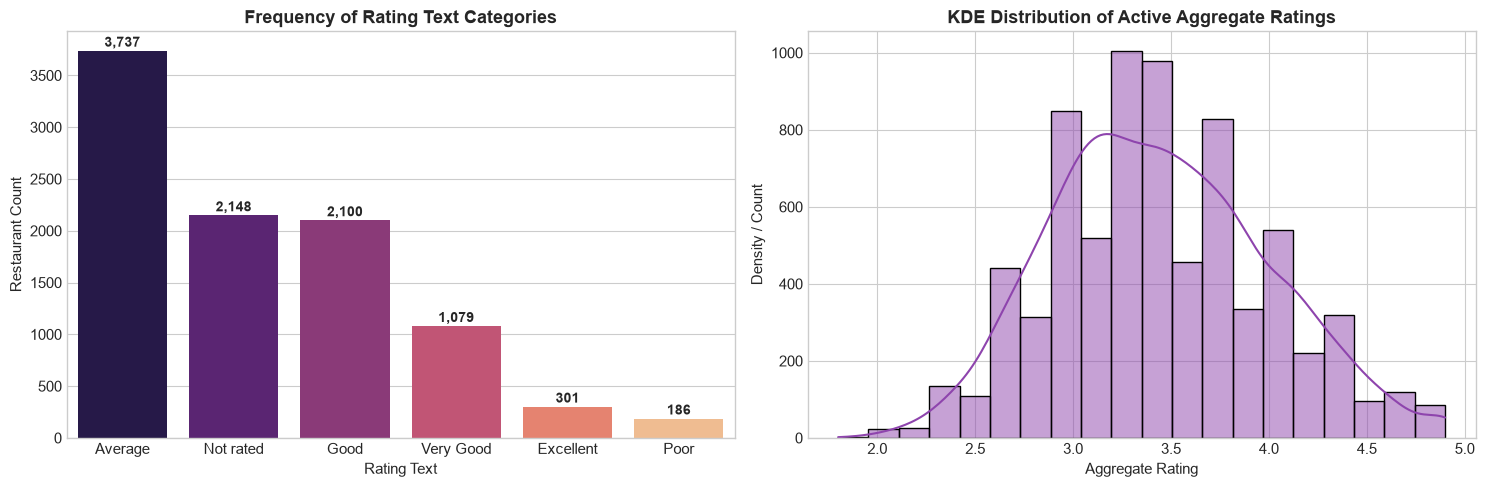

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Distribution of Rating Text categories
rating_text_counts = df['Rating text'].value_counts()
sns.barplot(x=rating_text_counts.index, y=rating_text_counts.values, palette='magma', ax=axes[0])
axes[0].set_title('Frequency of Rating Text Categories', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Rating Text')
axes[0].set_ylabel('Restaurant Count')
for i, v in enumerate(rating_text_counts.values):
    axes[0].text(i, v + 40, f"{v:,}", ha='center', fontweight='bold', fontsize=10)

# Histogram and KDE of Non-Zero Ratings
sns.histplot(df[df['Aggregate rating'] > 0]['Aggregate rating'], kde=True, bins=20, color='#8e44ad', ax=axes[1])
axes[1].set_title('KDE Distribution of Active Aggregate Ratings', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Aggregate Rating')
axes[1].set_ylabel('Density / Count')

plt.tight_layout()
plt.savefig('visualizations/comprehensive_rating_distribution.png', dpi=300)
plt.show()

### 3.2 Comparing Average Ratings Across Cuisines and Cities
Visualizing city and cuisine performance comparisons.

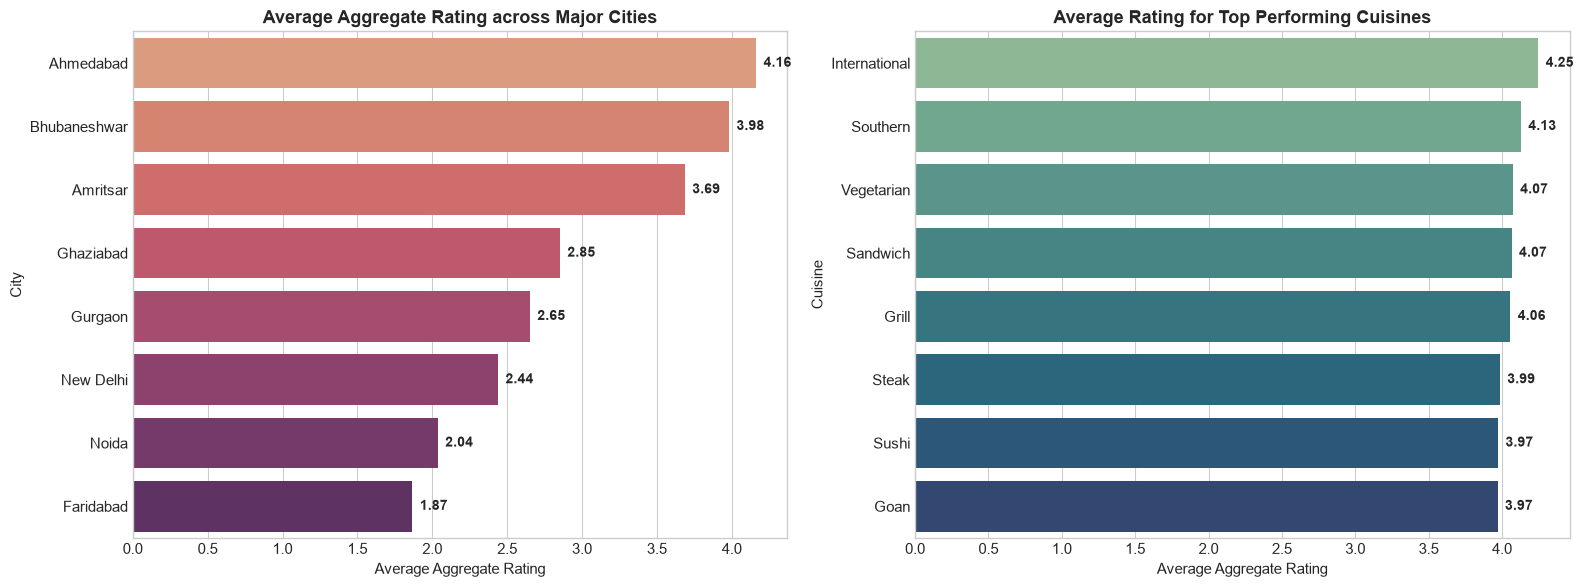

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# City comparison
top_cities = df['City'].value_counts().head(8).index
city_perf = df[df['City'].isin(top_cities)].groupby('City')['Aggregate rating'].mean().sort_values(ascending=False)

sns.barplot(x=city_perf.values, y=city_perf.index, palette='flare', ax=axes[0])
axes[0].set_title('Average Aggregate Rating across Major Cities', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Average Aggregate Rating')
axes[0].set_ylabel('City')
for i, v in enumerate(city_perf.values):
    axes[0].text(v + 0.05, i, f"{v:.2f}", va='center', fontweight='bold', fontsize=10)

# Cuisine comparison (Top 8 highest rated reliable cuisines)
top_cuisines_perf = reliable_cuisines.sort_values('Avg_Rating', ascending=False).head(8)
sns.barplot(x='Avg_Rating', y='Cuisine_Split', data=top_cuisines_perf, palette='crest', ax=axes[1])
axes[1].set_title('Average Rating for Top Performing Cuisines', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Average Aggregate Rating')
axes[1].set_ylabel('Cuisine')
for i, v in enumerate(top_cuisines_perf['Avg_Rating']):
    axes[1].text(v + 0.05, i, f"{v:.2f}", va='center', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.savefig('visualizations/city_and_cuisine_rating_comparison.png', dpi=300)
plt.show()

### 3.3 Visualizing Relationships Between Various Features and Target Variable
We analyze how `Price range`, `Votes`, and `Average Cost for two` interact with `Aggregate rating`.

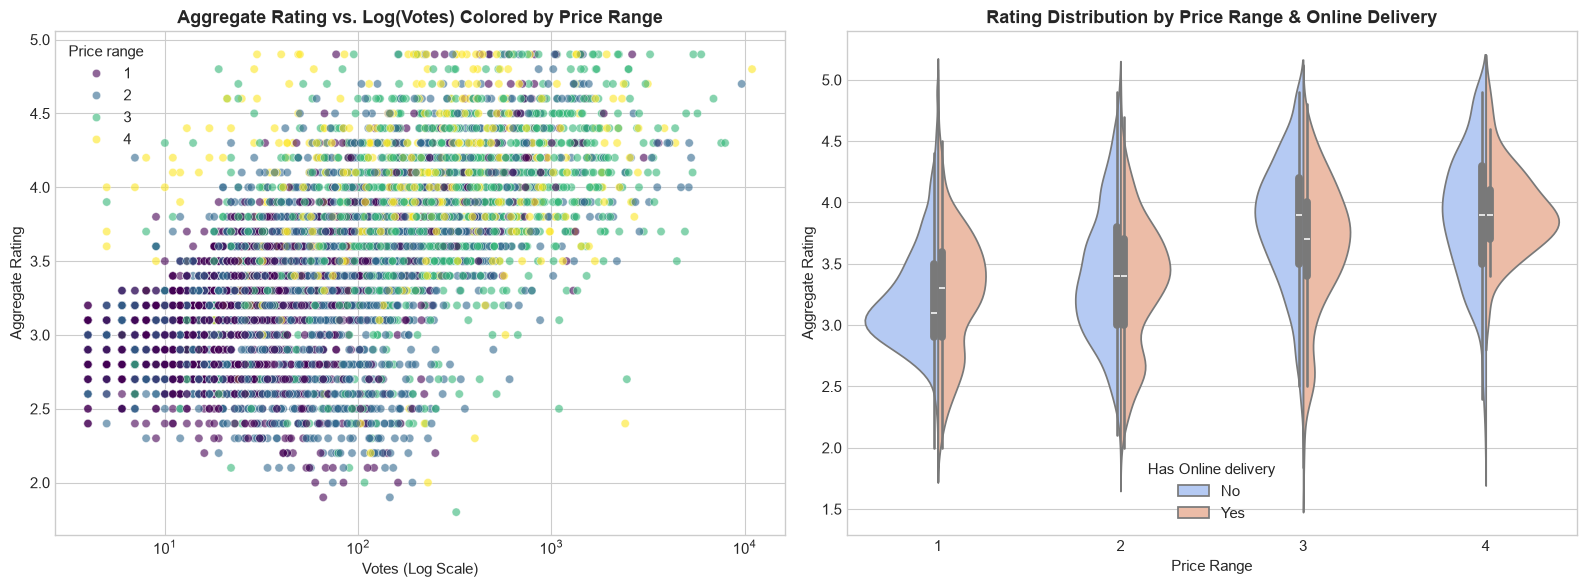

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Votes vs. Aggregate Rating (Log Scale on Votes to handle skew)
sns.scatterplot(data=df[df['Aggregate rating'] > 0], x='Votes', y='Aggregate rating', 
                hue='Price range', palette='viridis', alpha=0.6, ax=axes[0])
axes[0].set_xscale('log')
axes[0].set_title('Aggregate Rating vs. Log(Votes) Colored by Price Range', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Votes (Log Scale)')
axes[0].set_ylabel('Aggregate Rating')

# Price range & Online delivery violin plot
sns.violinplot(data=df[df['Aggregate rating'] > 0], x='Price range', y='Aggregate rating', 
               hue='Has Online delivery', split=True, palette='coolwarm', ax=axes[1])
axes[1].set_title('Rating Distribution by Price Range & Online Delivery', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Price Range')
axes[1].set_ylabel('Aggregate Rating')

plt.tight_layout()
plt.savefig('visualizations/multivariate_relationships.png', dpi=300)
plt.show()

---
## Level 3 Summary & Final Machine Learning Takeaways

1. **Predictive Performance:** The **Random Forest Regressor** demonstrated state-of-the-art predictive capability ($R^2 = 0.9532$, $RMSE = 0.3262$), far surpassing linear baselines.
2. **Key Predictive Driver:** Engagement volume (`Votes`) is the single strongest indicator of rating performance, supplemented by `Price range` and service tier features.
3. **Customer Preferences:** While volume demand is led by staple cuisines like **North Indian** and **Chinese**, top satisfaction ratings cluster in upscale specialty cuisines (**Continental**, **Italian**, **Cafe**).
4. **Actionable Business Recommendations for Restaurants:**
   - Enabling **online delivery** and **table booking** correlates with higher ratings and broader reach.
   - Restaurants should actively encourage customer voting/reviews, as higher engagement strongly associates with 4.0+ ratings.
   - Mid-range restaurants (Price Range 2 & 3) gain the greatest proportional boost from delivery partnerships.
